## 8 · Friction per user and the travel window

### By:
Sofía Arango Patiño

### Date:
2026-11-08

### Description:

An additional analysis of the final model ([issue #31](https://github.com/modsiw-mona/anomaly_detection_ato/issues/31);
thesis objective **OE4**). It uses the scores already saved by issues #6 and #7 and the alert thresholds fixed in
issue #7; **nothing is refitted or re-tuned**.

1. **Friction per user.** Notebook 07 measures friction per login (the share of logins challenged). Two studies on
   this dataset, Wiefling et al. (2022) and Rotter et al. (2025), measure it **per user**: they set the threshold so
   that a given share of takeovers is detected, and report how often each legitimate user would be asked to
   re-authenticate. This notebook computes that metric for the selected model, on both sides of the split, with
   bootstrap intervals, and for the Freeman et al. (2016) baseline of issue #5 on the same users, which is the
   comparison Rotter et al. make.
2. **Who carries the friction:** by how many logins a user has, and how much of it falls on first logins.
3. **The travel window:** the impossible-travel feature of issue #6 flags a country change within one hour of the
   previous login. How much does that window matter, and why is it not refined by distance?

Charts and a JSON report are written to `data/08_reporting/` (gitignored, like all data).

## Import libraries

In [1]:
import sys
from pathlib import Path

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import display

from data.datasets import load_dataset_config
from data.intermediate import intermediate_path
from data.split import load_side
from model.freeman import SCORE as FREEMAN
from model.freeman import freeman_scores
from model.friction import REAUTH_RATES, bootstrap_friction, challenged_counts, user_friction

pl.Config.set_tbl_rows(40)
pl.Config.set_fmt_str_lengths(50)
pl.Config.set_tbl_width_chars(200)

SURFACE, INK, INK_2, MUTED, GRID, AXIS = (
    "#fcfcfb",
    "#0b0b0b",
    "#52514e",
    "#898781",
    "#e1e0d9",
    "#c3c2b7",
)
BLUE, ORANGE = "#2a78d6", "#eb6834"  # categorical slots 1 and 2 of the validated palette
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 12, "axes.titleweight": "bold",
        "axes.titlelocation": "left", "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID,
        "grid.linewidth": 0.6, "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110,
    }
)  # fmt: skip


def subtitle(ax: plt.Axes, text: str) -> None:
    ax.text(0, 1.02, text, transform=ax.transAxes, color=INK_2, fontsize=9, va="bottom")


config = load_dataset_config("rba")
data_dir = REPO_ROOT / "data"
reports = data_dir / "08_reporting"
reports.mkdir(exist_ok=True)


def save(fig: plt.Figure, name: str) -> None:
    fig.savefig(reports / f"{config.name}_{name}.png", dpi=150, bbox_inches="tight")

## 1 · The metric

For a threshold $t$ and a legitimate user $u$ with $n_u$ legitimate logins, the **re-authentication rate** is

$$r_u(t) = \frac{\#\{\text{logins of } u \text{ with score} \ge t\}}{n_u},$$

and the friction of $t$ is the distribution of $r_u(t)$ over users: the median user (the number both studies
report), the mean, the 90th and 99th percentiles, and the share of users asked at least once. Takeover logins do
not enter $r_u$; they set the threshold.

Two kinds of thresholds:

* **The alert budgets of issue #7**, fixed on development data before the test side was opened: ask for 2FA from
  the riskiest 1% of logins, block from the riskiest 0.1%.
* **A detection rate**, as in the two studies: the highest threshold that still detects that share of the
  takeovers being evaluated. The four rates are those at which Rotter et al. (2025) report friction for the
  dataset's real takeovers (94.2, 89.7, 82.8 and 78.2%). This threshold is set on the very takeovers it is
  evaluated on, as those studies do, so it is **descriptive**: it shows the trade-off, it does not choose anything.

Scores used: development side, the out-of-fold scores of issue #6 (each login scored by a model that never saw its
user); test side, the final model's scores of issue #7.

## 2 · Load the saved scores

In [3]:
keys = pl.scan_parquet(data_dir / "04_feature" / f"{config.name}_features.parquet").select(
    "event_id", "user_id", "label_ato", "prior_successes"
)
freeman = freeman_scores(pl.scan_parquet(intermediate_path(config, data_dir)), config)
sides = {}
for side, file in (("development", "dev_oof"), ("test", "test_scores")):
    scores = pl.scan_parquet(data_dir / "07_model_output" / f"{config.name}_{file}.parquet")
    frame = scores.join(keys, on="event_id").join(freeman, on="event_id", how="left").collect()
    assert frame.height == scores.select(pl.len()).collect().item(), (
        "every scored login has its keys"
    )
    assert frame["event_id"].is_unique().all()
    sides[side] = frame
    print(
        f"{side}: {frame.height:,} logins, {frame['user_id'].n_unique():,} users, "
        f"{int(frame['label_ato'].sum())} takeovers ({int(frame.filter(pl.col('label_ato'))['prior_successes'].eq(0).sum())} on a first login)"
    )
assert int(sides["test"]["label_ato"].sum()) == 28, "the test side of issue #7"
metrics = json.loads((reports / f"{config.name}_test_metrics.json").read_text())
budgets = {
    "ask for 2FA (1%)": metrics["thresholds"]["step-up"],
    "block (0.1%)": metrics["thresholds"]["review / block"],
}
budgets

development: 7,868,084 logins, 2,215,023 users, 112 takeovers (41 on a first login)


test: 1,971,980 logins, 553,756 users, 28 takeovers (13 on a first login)


{'ask for 2FA (1%)': 0.0033330654337646514,
 'block (0.1%)': 0.03332510201888003}

## 3 · Friction at the alert budgets and at the detection rates

All logins, all users. Rates are shares of each user's legitimate logins.

In [4]:
def friction_table(
    frame: pl.DataFrame, score: str = "score", fixed: dict | None = None
) -> pl.DataFrame:
    result = user_friction(frame, thresholds=fixed, score=score)
    return pl.DataFrame(
        [{"threshold for": name, **values} for name, values in result.items()]
    ).with_columns(pl.col("threshold").round(5))


friction = {side: friction_table(frame, fixed=budgets) for side, frame in sides.items()}
for side, table in friction.items():
    print(f"{side}: {table['users'][0]:,} legitimate users")
    display(
        table.drop("users")
        .with_columns(
            [
                pl.col(c).mul(100).round(3).alias(f"{c} %")
                for c in ("detected", "median", "mean", "p90", "p99", "ever")
            ]
        )
        .drop("detected", "median", "mean", "p90", "p99", "ever")
    )

development: 2,215,004 legitimate users


threshold for,threshold,detected %,median %,mean %,p90 %,p99 %,ever %
str,f64,f64,f64,f64,f64,f64,f64
"""ask for 2FA (1%)""",0.00333,90.179,0.0,1.139,0.0,50.0,2.513
"""block (0.1%)""",0.03333,81.25,0.0,0.108,0.0,0.0,0.283
"""detect 94.2%""",0.0,100.0,100.0,100.0,100.0,100.0,100.0
"""detect 89.7%""",0.00333,90.179,0.0,1.097,0.0,50.0,2.416
"""detect 82.8%""",0.03,83.036,0.0,0.116,0.0,0.0,0.303
"""detect 78.2%""",0.04332,78.571,0.0,0.073,0.0,0.0,0.202


test: 553,756 legitimate users


threshold for,threshold,detected %,median %,mean %,p90 %,p99 %,ever %
str,f64,f64,f64,f64,f64,f64,f64
"""ask for 2FA (1%)""",0.00333,100.0,0.0,1.099,0.0,50.0,2.414
"""block (0.1%)""",0.03333,85.714,0.0,0.108,0.0,0.0,0.269
"""detect 94.2%""",0.01,96.429,0.0,0.418,0.0,0.0,0.944
"""detect 89.7%""",0.01333,92.857,0.0,0.288,0.0,0.0,0.658
"""detect 82.8%""",0.04999,85.714,0.0,0.061,0.0,0.0,0.16
"""detect 78.2%""",0.28328,78.571,0.0,0.003,0.0,0.0,0.007


**Uncertainty (test side).** 28 test takeovers: each one is 3.6 points of detection. The bootstrap resamples
the takeovers (legitimate logins held fixed, as for the PR-AUC interval of notebook 07), so the threshold for each
detection rate moves, and with it the friction.

In [5]:
intervals = bootstrap_friction(sides["test"], n_boot=2_000)
display(intervals.with_columns(pl.exclude("detection rate").mul(100).round(3)))

detection rate,mean low,mean high,ever low,ever high
f64,f64,f64,f64,f64
0.942,0.005,0.563,0.012,1.252
0.897,0.003,0.563,0.007,1.252
0.828,0.002,0.418,0.004,0.944
0.782,0.0,0.128,0.002,0.318


## 4 · Against the Freeman baseline, as Rotter et al. compare

Freeman et al. (2016) is the established risk-based authentication model (issue #5 re-implements it). It needs the
user's history, so it does not score an account's first login; the comparison is therefore made on **returning
logins** (the account had logged in successfully before), for both models, on the same users.

In [6]:
returning = {
    side: frame.filter(pl.col("prior_successes") > 0, pl.col(FREEMAN).is_not_null())
    for side, frame in sides.items()
}
rows = []
for side, frame in returning.items():
    for model, score in (("selected model", "score"), ("Freeman", FREEMAN)):
        for name, v in user_friction(frame, score=score).items():
            rows.append({"side": side, "model": model, "threshold for": name, "takeovers": int(frame["label_ato"].sum()),
                         "detected %": 100 * v["detected"], "median %": 100 * v["median"],
                         "mean %": 100 * v["mean"], "ever %": 100 * v["ever"]})  # fmt: skip
versus = pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(2))
versus

side,model,threshold for,takeovers,detected %,median %,mean %,ever %
str,str,str,i64,f64,f64,f64,f64
"""development""","""selected model""","""detect 94.2%""",71,100.0,100.0,100.0,100.0
"""development""","""selected model""","""detect 89.7%""",71,90.14,0.0,0.41,1.25
"""development""","""selected model""","""detect 82.8%""",71,83.1,0.0,0.09,0.31
"""development""","""selected model""","""detect 78.2%""",71,78.87,0.0,0.06,0.23
"""development""","""Freeman""","""detect 94.2%""",71,94.37,100.0,90.46,94.0
"""development""","""Freeman""","""detect 89.7%""",71,90.14,100.0,78.01,84.69
"""development""","""Freeman""","""detect 82.8%""",71,83.1,83.33,60.95,72.72
"""development""","""Freeman""","""detect 78.2%""",71,78.87,25.0,37.11,58.37
"""test""","""selected model""","""detect 94.2%""",15,100.0,0.0,0.08,0.29


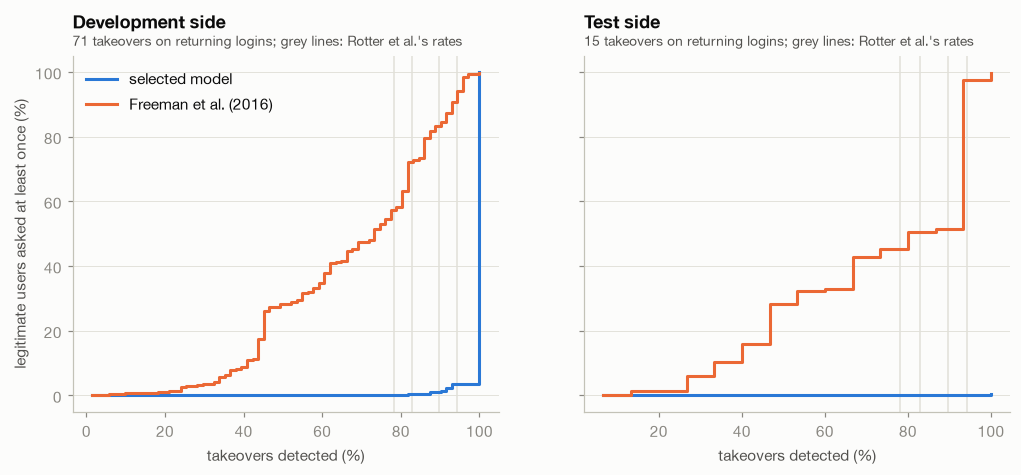

In [7]:
def curve(frame: pl.DataFrame, score: str) -> tuple[np.ndarray, np.ndarray]:
    positives = frame.filter(pl.col("label_ato"))[score].to_numpy()
    candidates = np.unique(positives)[::-1]  # highest threshold first
    _, counts = challenged_counts(frame, candidates.tolist(), score=score)
    detected = np.array([(positives >= t).mean() for t in candidates])
    return detected, (counts > 0).mean(axis=0)


fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
curves = {}
for ax, (side, frame) in zip(axes, returning.items(), strict=True):
    for model, score, color in (
        ("selected model", "score", BLUE),
        ("Freeman et al. (2016)", FREEMAN, ORANGE),
    ):
        x, y = curve(frame, score)
        curves[(side, model)] = (x, y)
        ax.plot(100 * x, 100 * y, drawstyle="steps-post", color=color, label=model)
    for rate in REAUTH_RATES:
        ax.axvline(100 * rate, color=GRID, lw=1, zorder=0)
    ax.set_xlabel("takeovers detected (%)")
    ax.grid(axis="y")
    ax.set_title(f"{side.capitalize()} side", pad=18)
    subtitle(
        ax,
        f"{int(frame['label_ato'].sum())} takeovers on returning logins; grey lines: Rotter et al.'s rates",
    )
axes[0].set_ylabel("legitimate users asked at least once (%)")
axes[0].legend(loc="upper left")
save(fig, "user_friction_vs_freeman")
plt.show()

## 5 · Who carries the friction

At the 2FA budget, test side: users grouped by how many legitimate logins they have in the data (about ten
months), and how much of the friction falls on an account's first login.

In [8]:
test = sides["test"]
step_up = budgets["ask for 2FA (1%)"]
legit = test.filter(~pl.col("label_ato")).with_columns(asked=pl.col("score") >= step_up)
per_user = legit.group_by("user_id").agg(logins=pl.len(), asked=pl.col("asked").sum())
groups = (
    pl.when(pl.col("logins") == 1).then(pl.lit("1"))
    .when(pl.col("logins") <= 4).then(pl.lit("2-4"))
    .when(pl.col("logins") <= 19).then(pl.lit("5-19"))
    .when(pl.col("logins") <= 39).then(pl.lit("20-39"))
    .otherwise(pl.lit("40+"))
)  # fmt: skip
ORDER = ["1", "2-4", "5-19", "20-39", "40+"]
history = (
    per_user.with_columns(group=groups, rate=pl.col("asked") / pl.col("logins"))
    .group_by("group")
    .agg(
        users=pl.len(),
        **{
            "median %": pl.col("rate").median() * 100,
            "mean %": pl.col("rate").mean() * 100,
            "asked at least once %": (pl.col("asked") > 0).mean() * 100,
        },
        challenges=pl.col("asked").sum(),
    )
    .with_columns(
        (pl.col("users") / pl.col("users").sum() * 100).alias("% of users"),
        (pl.col("challenges") / pl.col("challenges").sum() * 100).alias("% of 2FA requests"),
    )
    .sort(pl.col("group").replace_strict(ORDER, list(range(len(ORDER)))))
    .rename({"group": "legitimate logins of the user"})
    .with_columns(pl.col(pl.Float64).round(2))
)
first = legit.with_columns(first=pl.col("prior_successes") == 0)
first_share = first.filter("asked")["first"].mean()
print(
    f"first logins: {100 * first['first'].mean():.1f}% of legitimate logins, "
    f"{100 * first_share:.1f}% of the legitimate logins asked for 2FA"
)
history

first logins: 28.1% of legitimate logins, 39.9% of the legitimate logins asked for 2FA


legitimate logins of the user,users,median %,mean %,asked at least once %,challenges,% of users,% of 2FA requests
str,u32,f64,f64,f64,u32,f64,f64
"""1""",238949,0.0,1.32,1.32,3154,43.15,16.87
"""2-4""",204799,0.0,0.99,2.17,5224,36.98,27.95
"""5-19""",100540,0.0,0.81,4.55,6857,18.16,36.68
"""20-39""",7431,0.0,0.92,11.03,1799,1.34,9.62
"""40+""",2037,0.0,0.91,18.7,1658,0.37,8.87


## 6 · The travel window (development side)

The `travel` feature of issue #6 flags a **country change within one hour** of the account's previous login, a
time-only proxy for impossible travel. The window was a design choice; here it is varied from 15 minutes to any gap,
on the development side only (the test side is not used to tune features).

In [9]:
dev = (
    load_side(config, data_dir, "dev")
    .select(
        "user_id",
        "timestamp",
        "country",
        "prior_successes",
        "hours_since_prev_success",
        "new_country",
        "label_ato",
    )
    .collect()
    .sort("user_id", "timestamp")
)
dev = dev.with_columns(prev_country=pl.col("country").cast(pl.String).shift(1).over("user_id"))
known = dev.filter(pl.col("prior_successes") > 0, pl.col("prev_country").is_not_null())
changed = pl.col("country").cast(pl.String) != pl.col("prev_country")
ato, leg = known.filter(pl.col("label_ato")), known.filter(~pl.col("label_ato"))
rows = []
for hours in (0.25, 0.5, 1, 2, 3, 6, 12, 24, 168, None):
    flag = changed if hours is None else changed & (pl.col("hours_since_prev_success") < hours)
    a, b = ato.filter(flag).height, leg.filter(flag).height
    rows.append({"window": "any gap" if hours is None else f"{hours:g} h", "takeovers flagged": a,
                 "% of takeovers": 100 * a / ato.height, "legitimate flagged": b,
                 "% of legitimate": 100 * b / leg.height, "lift": (a / ato.height) / (b / leg.height) if b else None})  # fmt: skip
windows = pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(3))
print(f"returning logins with a known previous country: {known.height:,}; takeovers: {ato.height}")
print(f"new country for the account (any time): {ato['new_country'].sum()} of {ato.height} takeovers, "
      f"{100 * leg['new_country'].mean():.2f}% of legitimate logins")  # fmt: skip
windows

returning logins with a known previous country: 5,653,061; takeovers: 71
new country for the account (any time): 56 of 71 takeovers, 0.78% of legitimate logins


window,takeovers flagged,% of takeovers,legitimate flagged,% of legitimate,lift
str,i64,f64,i64,f64,f64
"""0.25 h""",5,7.042,3844,0.068,103.563
"""0.5 h""",5,7.042,4678,0.083,85.1
"""1 h""",6,8.451,5347,0.095,89.343
"""2 h""",8,11.268,6047,0.107,105.334
"""3 h""",9,12.676,6526,0.115,109.803
"""6 h""",9,12.676,7477,0.132,95.837
"""12 h""",10,14.085,8791,0.156,90.569
"""24 h""",11,15.493,11736,0.208,74.626
"""168 h""",22,30.986,25651,0.454,68.287


**Can the window follow distance instead (kilometres per hour, as industry "impossible travel" rules do)?**
Only if the countries are real. The dataset card says the geography was synthesised; the legitimate logins that
change country within an hour show what that means:

In [10]:
fast = leg.filter(changed & (pl.col("hours_since_prev_success") < 1))
pairs = (
    fast.group_by(pl.min_horizontal("prev_country", pl.col("country").cast(pl.String)).alias("country a"),
                  pl.max_horizontal("prev_country", pl.col("country").cast(pl.String)).alias("country b"))
    .len("legitimate changes within 1 h")
    .sort("legitimate changes within 1 h", descending=True)
    .head(8)
)  # fmt: skip
pairs

country a,country b,legitimate changes within 1 h
str,str,u32
"""BR""","""NO""",699
"""PL""","""RO""",393
"""FR""","""NO""",317
"""NL""","""NO""",283
"""IT""","""NO""",258
"""ID""","""NO""",250
"""RO""","""US""",209
"""DK""","""NO""",174


In [11]:
(reports / f"{config.name}_user_friction.json").write_text(json.dumps({
    "alert_budgets_and_rates": {side: table.to_dicts() for side, table in friction.items()},
    "test_bootstrap": intervals.to_dicts(),
    "returning_vs_freeman": versus.to_dicts(),
    "history_groups_test_2fa": history.to_dicts(),
    "first_login_share_of_2fa_test": float(first_share),
    "travel_windows_dev": windows.to_dicts(),
}, indent=2))  # fmt: skip
print("report written")

report written


## Conclusions

* **At the alert budgets of issue #7, the median legitimate user is never asked to re-authenticate.** On the test
  side, the 2FA tier (riskiest 1% of logins) asks **2.4% of users** at least once in about ten months, and the
  average user on 1.1% of their logins (about one login in 90). The block tier reaches 0.27% of users. The
  development side gives the same figures (2.5% and 0.28%), so the friction transfers to new users like the
  thresholds do.
* **At the detection rates Rotter et al. (2025) report** (78.2 to 94.2% of takeovers), the median test user is
  never asked, the average user is asked on 0.003 to 0.42% of logins, and 0.01 to 0.94% of users are ever asked.
  With 28 test takeovers this is uncertain: resampling them, the mean stays below 0.6% of logins and the share of
  users ever asked below 1.3% (95% intervals).
* **The ceiling is the features, not the threshold.** On the development side, 94.2% detection cannot be reached
  without asking every user: the last takeovers score 0, as the error analysis of notebook 07 found (first logins
  with common client values). Up to about 90% detection, the cost stays near 2.4% of users.
* **Against Freeman et al. (2016), the established risk-based authentication model, on the same returning logins,**
  the selected model needs far less friction. To detect 80 to 100% of the test takeovers, Freeman asks 51 to 100% of
  users at least once, and its median user re-authenticates on 5 to 100% of their logins; the selected model asks at
  most 0.3% of users. The development side agrees (Freeman: 58 to 94% of users) up to 90% detection; at 94% both
  reach almost every user. This is the same direction as Rotter et al., whose neural network also clearly beats
  Freeman's model on this dataset, with different features and protocol.
* **Who carries the friction:** the share of each user's logins that are challenged is similar whatever the
  history length (0.8 to 1.3%), but users with many logins have more chances to be asked once (1.3% of users with a
  single login, 18.7% of users with 40 or more). **First logins carry 40% of the 2FA requests** while being 28% of
  logins: cold start is the main source of friction, as it is the main source of missed takeovers.
* **The travel window hardly matters.** From 15 minutes to 12 hours the impossible-travel flag catches 5 to 10 of 71
  development takeovers with a lift of 85 to 110; a week or any gap dilutes it (lift 68 and 59). Most of the
  geographic signal is the account's new country (56 of 71 takeovers, 0.78% of legitimate logins), which the model
  already has. A distance-based rule cannot be tested: the geography is synthetic (699 legitimate changes between
  Brazil and Norway within an hour). The one-hour window stays; distance-based travel is future work on real data.
* **Limits.** Per-user rates depend on how many logins users have (43% of test users have a single legitimate login,
  so their rate is 0 or 100%). Thresholds at a detection rate are set on the takeovers they are evaluated on, as in
  the two studies, so they describe the trade-off rather than choose a policy. Freeman's model is this project's
  re-implementation, with the simplifications documented in issue #5. Comparisons with published numbers are
  indicative: other features, other positives (Rotter et al. add simulated attacks) and no label window.

These results complete **OE4** with the per-user view of friction used by the studies on this dataset.
